In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import cv2
import matplotlib.pyplot as plt
import numpy as np

from src.vision.synthetic_generator import gerar_amostra_cordao_solda, gerar_amostra_termografia_haz
from src.vision.weld_inspection import inspecionar_cordao_solda
from src.vision.thermal_haz import analisar_haz_termica

# Criar ficheiros de imagem na pasta data/test_images
caminho_solda = Path("../data/test_images/weld/solda_teste.png")
caminho_termo = Path("../data/test_images/thermal/termografia_teste.png")

gerar_amostra_cordao_solda(caminho_solda, com_poros=True, com_descontinuidade=False)
gerar_amostra_termografia_haz(caminho_termo, com_ponto_quente_critico=True)

print("Amostras sintéticas geradas com sucesso.")

Amostras sintéticas geradas com sucesso.


--- Diagnóstico Óptico do Cordão de Soldadura ---
Status: APROVADO
Taxa de Porosidade: 0.04%
Poros Identificados: 2


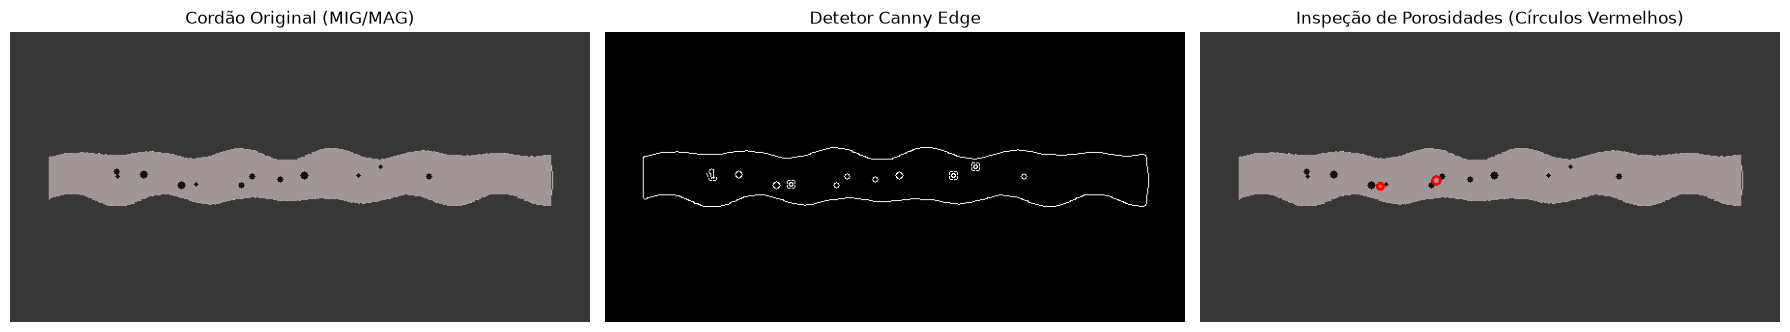

In [2]:
img_solda = cv2.imread(str(caminho_solda))
resultado_solda = inspecionar_cordao_solda(img_solda)

print("--- Diagnóstico Óptico do Cordão de Soldadura ---")
print(f"Status: {'APROVADO' if resultado_solda['aprovado'] else 'REPROVADO'}")
print(f"Taxa de Porosidade: {resultado_solda['taxa_porosidade_pct']}%")
print(f"Poros Identificados: {resultado_solda['total_poros_detetados']}")

# Visualização com destaque dos contornos detetados
img_anotada = img_solda.copy()
for poro in resultado_solda["detalhes_poros"]:
    cv2.circle(img_anotada, poro["centro"], poro["raio"] + 2, (0, 0, 255), 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(cv2.cvtColor(img_solda, cv2.COLOR_BGR2RGB))
axes[0].set_title("Cordão Original (MIG/MAG)")
axes[0].axis("off")

axes[1].imshow(resultado_solda["mascaras"]["bordos_canny"], cmap="gray")
axes[1].set_title("Detetor Canny Edge")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(img_anotada, cv2.COLOR_BGR2RGB))
axes[2].set_title("Inspeção de Porosidades (Círculos Vermelhos)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

--- Diagnóstico Termográfico da HAZ ---
Risco de Trinca Térmica: SIM (CRÍTICO)
Área Crítica Sobreaquecida: 3667 px (2.037%)
Hotspots Localizados: 1


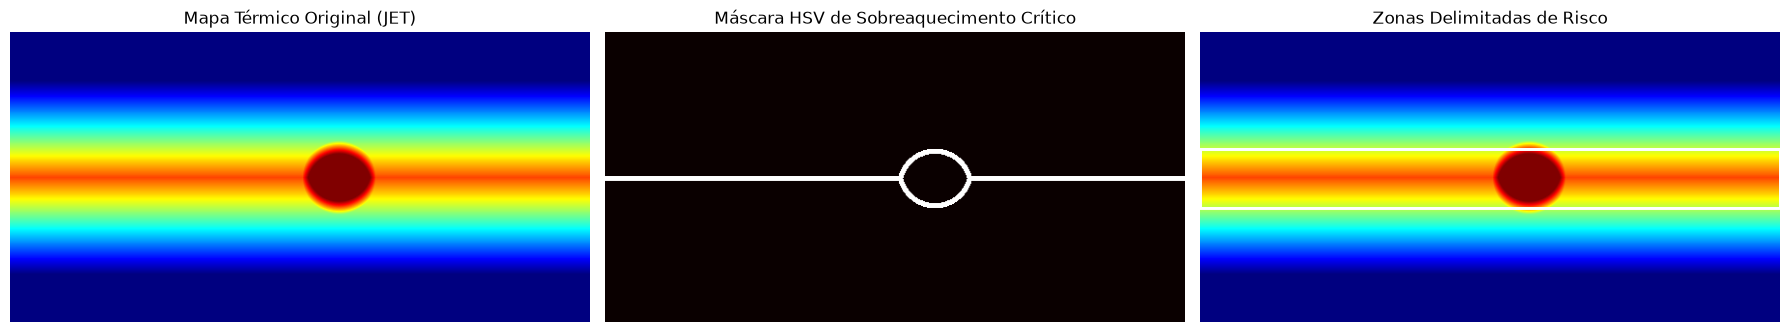

In [3]:
img_termo = cv2.imread(str(caminho_termo))
resultado_termo = analisar_haz_termica(img_termo)

print("--- Diagnóstico Termográfico da HAZ ---")
print(f"Risco de Trinca Térmica: {'SIM (CRÍTICO)' if resultado_termo['risco_trinca_termica'] else 'NÃO'}")
print(f"Área Crítica Sobreaquecida: {resultado_termo['area_critica_px']} px ({resultado_termo['percentagem_haz_critica']}%)")
print(f"Hotspots Localizados: {resultado_termo['quantidade_hotspots']}")

img_termo_anotada = img_termo.copy()
for spot in resultado_termo["hotspots"]:
    x, y, w, h = spot["bbox"]
    cv2.rectangle(img_termo_anotada, (x, y), (x + w, y + h), (255, 255, 255), 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(cv2.cvtColor(img_termo, cv2.COLOR_BGR2RGB))
axes[0].set_title("Mapa Térmico Original (JET)")
axes[0].axis("off")

axes[1].imshow(resultado_termo["mascara_critica"], cmap="hot")
axes[1].set_title("Máscara HSV de Sobreaquecimento Crítico")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(img_termo_anotada, cv2.COLOR_BGR2RGB))
axes[2].set_title("Zonas Delimitadas de Risco")
axes[2].axis("off")

plt.tight_layout()
plt.show()